# Chapter 9 — Deep Backprop Networks

Companion notebook to Stone (2020), *Artificial Intelligence Engines*, Chapter 9.
All models are built from the small layer library `aie.layers` and the code in `scripts/deep_backprop.py`.

1. Convolutional networks: a LeNet-style CNN vs an MLP on shifted digits (Sections 9.2–9.4)
2. ReLU, vanishing gradients and residual networks (Sections 9.5, 9.7)
3. Denoising autoencoders (Section 9.9)
4. Fooling neural networks: the fast gradient sign method (Section 9.10)
5. Generative adversarial networks (Section 9.11)

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt

from aie.data import digits
from aie.losses import mean_sse
from scripts.deep_backprop import (
    GAN, accuracy, as_images, autoencoder, corrupt, deep_mlp, fgsm, input_gradient,
    layer_gradient_norms, lenet, mlp_classifier, predict_logits, ring_of_gaussians,
    train_classifier, train_denoising_autoencoder,
)
t_start = time.time()

## 1. Convolutional networks (Sections 9.2–9.4)

Each unit in a feature map computes a weighted sum over a small receptive field (Eq 9.2),

$$v(a,b) = \sum_{\alpha=-k}^{k}\sum_{\beta=-k}^{k} w(\alpha,\beta)\, x(a+\alpha, b+\beta),$$

and **all units in a feature map share the same weights** $w$, so a feature map detects one feature anywhere in the image.
Pooling (Section 9.4) then summarises small neighbourhoods, giving some invariance to small shifts.

Our offline MNIST stand-in `aie.data.digits()` places 7×5 digit glyphs on a 12×12 canvas, randomly shifted by up to `max_shift` pixels.
We use a scaled-down LeNet: conv3×3(6 maps) → ReLU → maxpool → conv3×3(12 maps) → ReLU → maxpool → dense(30) → dense(10).

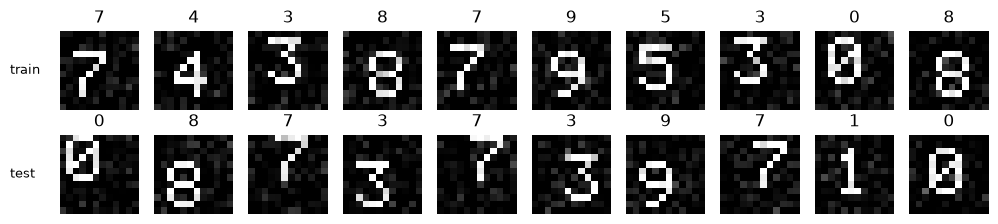

In [2]:
X_train, y_train = digits(n_per_class=100, max_shift=1, seed=0)   # mildly shifted
X_test, y_test = digits(n_per_class=50, max_shift=2, seed=1)      # larger shifts, new noise
fig, axes = plt.subplots(2, 10, figsize=(10, 2.3))
for i in range(10):
    axes[0, i].imshow(X_train[i], cmap="gray"); axes[0, i].set_title(y_train[i])
    axes[1, i].imshow(X_test[i], cmap="gray"); axes[1, i].set_title(y_test[i])
for ax in axes.flat: ax.axis("off")
axes[0, 0].text(-8, 6, "train", fontsize=9); axes[1, 0].text(-8, 6, "test", fontsize=9)
plt.tight_layout(); plt.show()

CNN parameters: 4300,  MLP parameters: 9930


trained in 1.5s
CNN: train acc 1.000, shifted-test acc 0.602
MLP: train acc 1.000, shifted-test acc 0.410


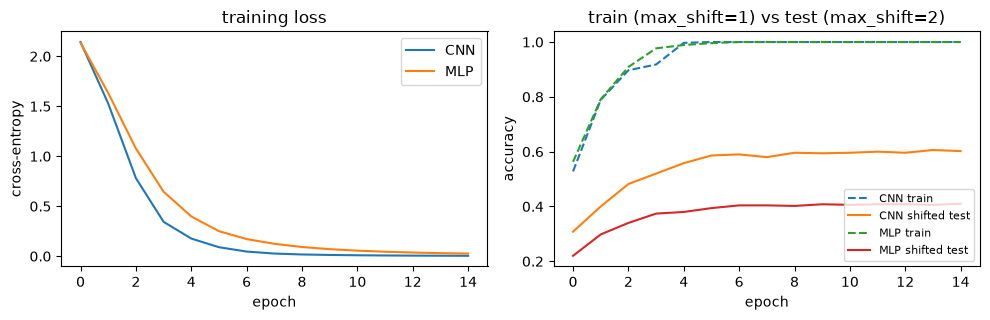

In [3]:
cnn = lenet(np.random.default_rng(0))
mlp = mlp_classifier(n_hidden=64, rng=np.random.default_rng(0))
n_cnn = sum(p.size for p, *_ in cnn.parameters()); n_mlp = sum(p.size for p, *_ in mlp.parameters())
print(f"CNN parameters: {n_cnn},  MLP parameters: {n_mlp}")

t0 = time.time()
h_cnn = train_classifier(cnn, as_images(X_train), y_train, n_epochs=15, lr=3e-3,
                         X_val=as_images(X_test), y_val=y_test)
h_mlp = train_classifier(mlp, X_train, y_train, n_epochs=15, lr=3e-3, X_val=X_test, y_val=y_test)
print(f"trained in {time.time() - t0:.1f}s")
print(f"CNN: train acc {h_cnn['acc'][-1]:.3f}, shifted-test acc {h_cnn['val_acc'][-1]:.3f}")
print(f"MLP: train acc {h_mlp['acc'][-1]:.3f}, shifted-test acc {h_mlp['val_acc'][-1]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for h, name in [(h_cnn, "CNN"), (h_mlp, "MLP")]:
    ax[0].plot(h["loss"], label=name)
    ax[1].plot(h["acc"], "--", label=f"{name} train"); ax[1].plot(h["val_acc"], label=f"{name} shifted test")
ax[0].set(xlabel="epoch", ylabel="cross-entropy", title="training loss")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="train (max_shift=1) vs test (max_shift=2)")
ax[0].legend(); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

Both networks fit the training set perfectly, but the CNN generalises much better to digits shifted further than anything it saw in training:
weight sharing plus pooling builds in (approximate) translation invariance, whereas the MLP must learn every position separately.

If the training set *does* contain the larger shifts, both do better — but the CNN still wins, with far fewer parameters:

In [4]:
X_s, y_s = digits(n_per_class=100, max_shift=2, seed=2)
cnn2, mlp2 = lenet(np.random.default_rng(0)), mlp_classifier(rng=np.random.default_rng(0))
train_classifier(cnn2, as_images(X_s), y_s, n_epochs=15, lr=3e-3)
train_classifier(mlp2, X_s, y_s, n_epochs=15, lr=3e-3)
print(f"trained on max_shift=2:  CNN test acc {accuracy(cnn2, as_images(X_test), y_test):.3f},"
      f"  MLP test acc {accuracy(mlp2, X_test, y_test):.3f}")

trained on max_shift=2:  CNN test acc 0.998,  MLP test acc 0.932


Learned first-layer kernels (each defines one feature map) and the feature maps they produce for one test digit (cf. Figs 9.3–9.4):

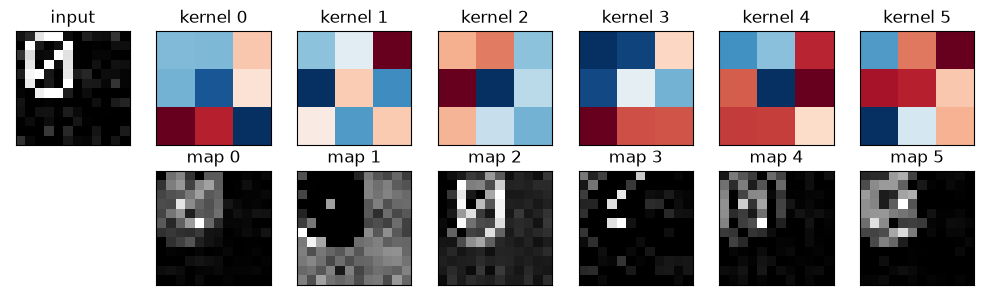

In [5]:
W1 = cnn.layers[0].params["W"]
x0 = as_images(X_test[:1])
maps = cnn.layers[1].forward(cnn.layers[0].forward(x0))[0]
fig, axes = plt.subplots(2, 7, figsize=(10, 3))
axes[0, 0].imshow(X_test[0], cmap="gray"); axes[0, 0].set_title("input")
axes[1, 0].axis("off")
for i in range(6):
    axes[0, i + 1].imshow(W1[i, 0], cmap="RdBu_r"); axes[0, i + 1].set_title(f"kernel {i}")
    axes[1, i + 1].imshow(maps[i], cmap="gray"); axes[1, i + 1].set_title(f"map {i}")
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 2. ReLU, vanishing gradients and residual networks (Sections 9.5, 9.7)

In backprop the error gradient at layer $\ell$ is a product of one factor per layer above it.
For sigmoid units each factor contains $\sigma'(u) = y(1-y) \le 1/4$ (Eq 4.2), so in a deep network the gradient **vanishes** exponentially towards the input.
ReLU units (Fig 9.8) have derivative exactly 1 when active, which is one reason AlexNet used them.

A residual block (Fig 9.9) learns the residual $F(x) = H(x) - x$ (Eq 9.3) and outputs $H(x) = x + F(x)$.
Its backward pass is $\partial E/\partial x = \partial E/\partial H\,(I + \partial F/\partial x)$: the identity path carries the gradient straight through.

`Residual` in `scripts/deep_backprop.py` is a `Layer` implementing exactly this (and is gradient-checked in the tests). Below: $\|\partial E/\partial W\|$ for every layer of 20-hidden-layer MLPs at initialisation.

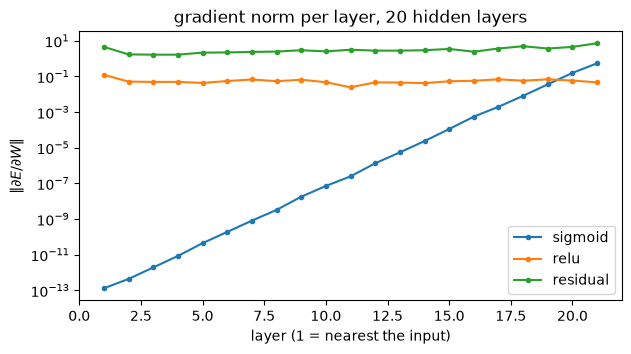

In [6]:
Xf_train = X_train.reshape(len(X_train), -1)
Xf_test = X_test.reshape(len(X_test), -1)
kinds = ["sigmoid", "relu", "residual"]
plt.figure(figsize=(7, 3.5))
for kind in kinds:
    norms = layer_gradient_norms(deep_mlp(kind, depth=20, rng=np.random.default_rng(0)),
                                 Xf_train[:200], y_train[:200])
    plt.semilogy(np.arange(1, len(norms) + 1), norms, "o-", ms=3, label=kind)
plt.xlabel("layer (1 = nearest the input)"); plt.ylabel(r"$\|\partial E/\partial W\|$")
plt.title("gradient norm per layer, 20 hidden layers"); plt.legend(); plt.show()

In the sigmoid network the gradient reaching the first layers is many orders of magnitude smaller than at the output (it underflows to exactly 0), so those layers barely learn.
The consequences for training (same data, optimiser and learning rate):

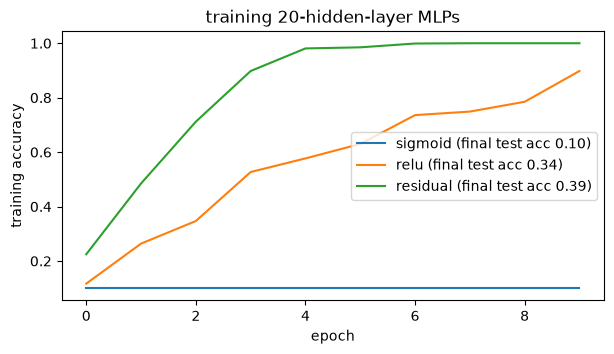

In [7]:
plt.figure(figsize=(7, 3.5))
for kind in kinds:
    net = deep_mlp(kind, depth=20, rng=np.random.default_rng(0))
    h = train_classifier(net, Xf_train, y_train, n_epochs=10, lr=1e-3, X_val=Xf_test, y_val=y_test)
    plt.plot(h["acc"], label=f"{kind} (final test acc {h['val_acc'][-1]:.2f})")
plt.xlabel("epoch"); plt.ylabel("training accuracy"); plt.title("training 20-hidden-layer MLPs")
plt.legend(); plt.show()

The deep sigmoid net is stuck at chance (10%), the plain ReLU net learns slowly, and the residual net trains fastest.

## 3. Denoising autoencoders (Section 9.9)

A denoising autoencoder is trained to map a *corrupted* input $\tilde{x}$ back to the clean $x$, minimising $E = \frac{1}{T}\sum_t \frac12 \|\hat{x}(\tilde{x}_t) - x_t\|^2$.
Following Vincent et al. (2010) we corrupt by zeroing 30% of pixels and adding Gaussian noise; fresh corruption is drawn every epoch.
Architecture: 144 → 64 (ReLU) → 144 (sigmoid). Here the clean targets are noise-free digits (`noise=0`) with shifts up to 2 pixels.

untrained AE error on corrupted test digits: 18.291
error of the corrupted input itself:         3.253


trained AE error on corrupted test digits:   1.479


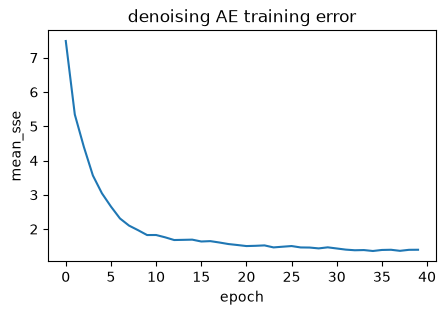

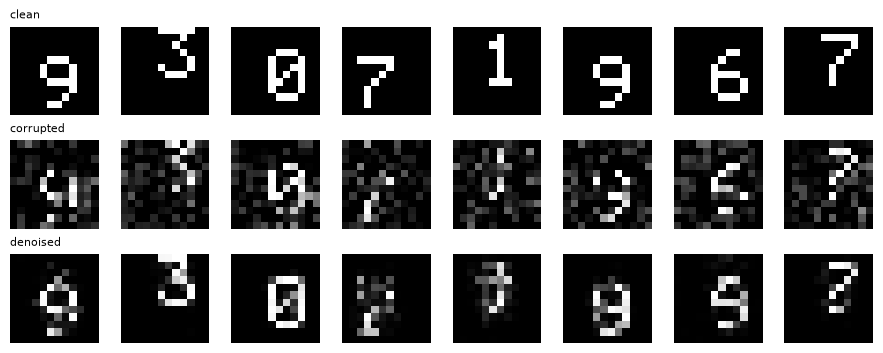

In [8]:
Xae_train = digits(n_per_class=100, noise=0.0, max_shift=2, seed=3)[0].reshape(1000, -1)
Xae_test = digits(n_per_class=20, noise=0.0, max_shift=2, seed=4)[0].reshape(200, -1)
ae = autoencoder(n_hidden=64, rng=np.random.default_rng(0))
Xc_test = corrupt(Xae_test, np.random.default_rng(1))
print(f"untrained AE error on corrupted test digits: {mean_sse(ae.forward(Xc_test), Xae_test):.3f}")
print(f"error of the corrupted input itself:         {mean_sse(Xc_test, Xae_test):.3f}")
h_ae = train_denoising_autoencoder(ae, Xae_train, n_epochs=40, lr=1e-2)
recon = ae.forward(Xc_test)
print(f"trained AE error on corrupted test digits:   {mean_sse(recon, Xae_test):.3f}")
plt.figure(figsize=(5, 3)); plt.plot(h_ae); plt.xlabel("epoch"); plt.ylabel("mean_sse")
plt.title("denoising AE training error"); plt.show()

fig, axes = plt.subplots(3, 8, figsize=(9, 3.6))
for i in range(8):
    for r, (img, lab) in enumerate([(Xae_test, "clean"), (Xc_test, "corrupted"), (recon, "denoised")]):
        axes[r, i].imshow(img[i].reshape(12, 12), cmap="gray", vmin=0, vmax=1)
        axes[r, i].axis("off")
        if i == 0: axes[r, i].set_title(lab, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

## 4. Fooling neural networks (Section 9.10)

For a linear unit $y = w\cdot x$, the input change of fixed size that alters $y$ the most is along $\nabla_x y = w$ (Eqs 9.4–9.7).
For a deep network we use the gradient of the error with respect to the **input**, $\nabla_x E$ — which backprop computes anyway: it is what `Sequential.backward` returns.
The **fast gradient sign method** perturbs each pixel by $\epsilon$ in the direction that increases the error:

$$x' = x + \epsilon\,\mathrm{sign}(\nabla_x E).$$

We attack the CNN from Section 1 that was trained on `max_shift=2` digits (99.8% test accuracy).

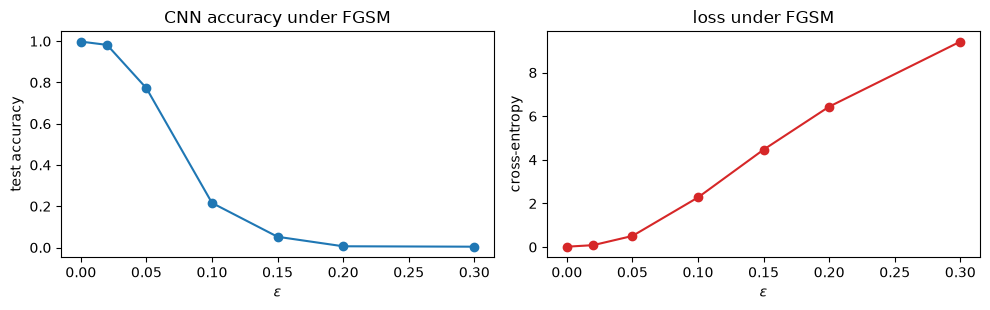

{0.0: np.float64(0.998), 0.02: np.float64(0.982), 0.05: np.float64(0.772), 0.1: np.float64(0.216), 0.15: np.float64(0.052), 0.2: np.float64(0.006), 0.3: np.float64(0.004)}


In [9]:
Xi_test = as_images(X_test)
eps_list = [0.0, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3]
accs, losses = [], []
for eps in eps_list:
    Xa = fgsm(cnn2, Xi_test, y_test, eps) if eps > 0 else Xi_test
    accs.append(accuracy(cnn2, Xa, y_test)); losses.append(input_gradient(cnn2, Xa, y_test)[0])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(eps_list, accs, "o-"); ax[0].set(xlabel=r"$\epsilon$", ylabel="test accuracy", title="CNN accuracy under FGSM")
ax[1].plot(eps_list, losses, "o-", c="C3"); ax[1].set(xlabel=r"$\epsilon$", ylabel="cross-entropy", title="loss under FGSM")
plt.tight_layout(); plt.show()
print(dict(zip(eps_list, np.round(accs, 3))))

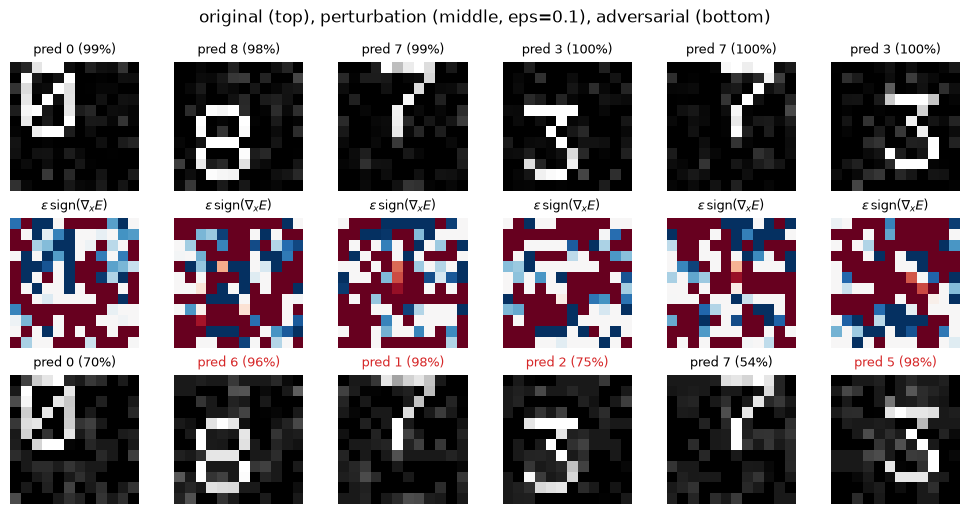

In [10]:
eps = 0.1
P0 = predict_logits(cnn2, Xi_test); correct = np.where(P0.argmax(1) == y_test)[0][:6]
Xa = fgsm(cnn2, Xi_test[correct], y_test[correct], eps)
Pa = predict_logits(cnn2, Xa)
softmax = lambda a: np.exp(a - a.max(1, keepdims=True)) / np.exp(a - a.max(1, keepdims=True)).sum(1, keepdims=True)
p0, pa = softmax(P0[correct]), softmax(Pa)
fig, axes = plt.subplots(3, 6, figsize=(10, 5.2))
for j, i in enumerate(correct):
    axes[0, j].imshow(Xi_test[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, j].set_title(f"pred {p0[j].argmax()} ({p0[j].max():.0%})", fontsize=9)
    axes[1, j].imshow(Xa[j, 0] - Xi_test[i, 0], cmap="RdBu_r", vmin=-eps, vmax=eps)
    axes[1, j].set_title(r"$\epsilon\,$sign$(\nabla_x E)$", fontsize=9)
    axes[2, j].imshow(Xa[j, 0], cmap="gray", vmin=0, vmax=1)
    axes[2, j].set_title(f"pred {pa[j].argmax()} ({pa[j].max():.0%})", fontsize=9, color="C3" if pa[j].argmax() != y_test[i] else "k")
for ax in axes.flat: ax.axis("off")
plt.suptitle(f"original (top), perturbation (middle, eps={eps}), adversarial (bottom)"); plt.tight_layout(); plt.show()

A perturbation of ±0.1 per pixel — small compared with the pixel range [0, 1] and the image noise — flips most predictions, often with high confidence (cf. Fig 9.12).

## 5. Generative adversarial networks (Section 9.11)

A generator $G(z)$ maps noise $z \sim \mathcal{N}(0, I)$ to samples; a discriminator outputs $D(x) = \sigma(a(x))$, the probability that $x$ came from the training data.
The discriminator ascends (Eq 9.9)

$$E_D = \frac{1}{m}\sum_{i}\left[\log D(x_i) + \log\big(1 - D(G(z_i))\big)\right],$$

i.e. it minimises the binary cross-entropy of its logits (computed stably by `bce_with_logits`, whose gradient is $(\sigma(a) - t)/m$).
Instead of descending Eq 9.10, $\frac1m\sum\log(1 - D(G(z_i)))$, the generator minimises the **non-saturating** loss $-\frac1m\sum\log D(G(z_i))$, which has the same goal but does not vanish when $D$ confidently rejects early fakes.
The generator's gradient is obtained by backpropagating through $D$ into $G$.

Toy data: a mixture of 8 Gaussians on a circle of radius 2. Both networks are 2-hidden-layer ReLU MLPs with 64 units.

GAN trained in 1.6s


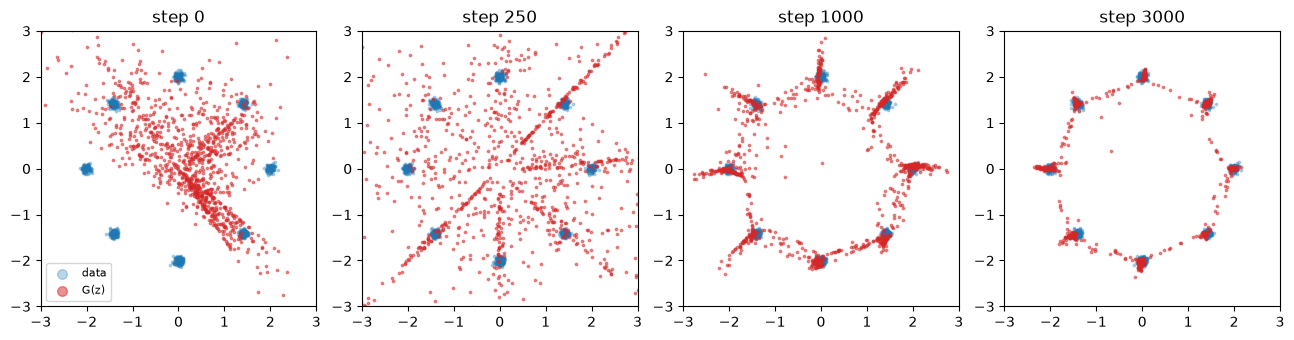

In [11]:
gan = GAN(z_dim=2, x_dim=2, n_hidden=64, seed=0)
snapshots = {}
t0 = time.time()
hist = {"d_loss": [], "g_loss": []}
for step in [0, 250, 1000, 3000]:
    done = len(hist["d_loss"])
    if step > done:
        h = gan.train(ring_of_gaussians, n_steps=step - done, batch_size=128)
        hist["d_loss"] += h["d_loss"]; hist["g_loss"] += h["g_loss"]
    snapshots[step] = gan.generate(np.random.default_rng(0).standard_normal((1000, 2)))
print(f"GAN trained in {time.time() - t0:.1f}s")

real = ring_of_gaussians(1000, np.random.default_rng(1))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, (step, fake) in zip(axes, snapshots.items()):
    ax.scatter(real[:, 0], real[:, 1], s=3, alpha=0.3, label="data")
    ax.scatter(fake[:, 0], fake[:, 1], s=3, alpha=0.5, c="C3", label="G(z)")
    ax.set(xlim=(-3, 3), ylim=(-3, 3), aspect="equal", title=f"step {step}")
axes[0].legend(markerscale=4, fontsize=8); plt.tight_layout(); plt.show()

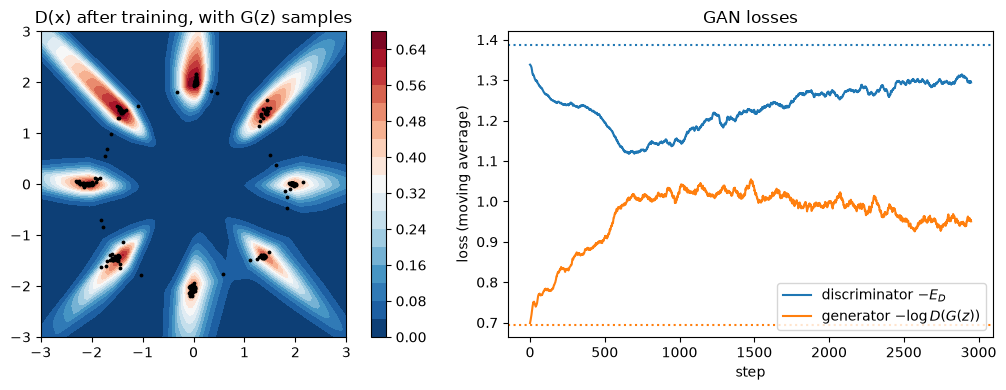

In [12]:
gx, gy = np.meshgrid(np.linspace(-3, 3, 120), np.linspace(-3, 3, 120))
Dgrid = gan.discriminate(np.stack([gx.ravel(), gy.ravel()], 1)).reshape(gx.shape)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cs = ax[0].contourf(gx, gy, Dgrid, levels=20, cmap="RdBu_r"); plt.colorbar(cs, ax=ax[0])
ax[0].scatter(*snapshots[3000][:300].T, s=3, c="k")
ax[0].set(aspect="equal", title="D(x) after training, with G(z) samples")
k = 50
smooth = lambda v: np.convolve(v, np.ones(k) / k, mode="valid")
ax[1].plot(smooth(hist["d_loss"]), label=r"discriminator $-E_D$")
ax[1].plot(smooth(hist["g_loss"]), label=r"generator $-\log D(G(z))$")
ax[1].axhline(2 * np.log(2), ls=":", c="C0"); ax[1].axhline(np.log(2), ls=":", c="C1")
ax[1].set(xlabel="step", ylabel="loss (moving average)", title="GAN losses"); ax[1].legend()
plt.tight_layout(); plt.show()

At the equilibrium $p_G = p_x$ the optimal discriminator is $D^*(x) = p_x/(p_x + p_G) = 1/2$ (Eq 9.8), so $-E_D \to 2\log 2$ and $-\log D(G(z)) \to \log 2$ (dotted lines).
The losses hover near these values: the generator has learned to put its samples on the modes of the ring, and the discriminator can no longer tell them apart reliably.
(GAN training is an arms race rather than a minimisation, so the curves oscillate rather than converge.)

In [13]:
print(f"total notebook compute time: {time.time() - t_start:.1f}s")

total notebook compute time: 6.9s
